# 08 - Nén model (quantization) mất bao nhiêu chất lượng?

**Đo cái gì?** So cùng một model ở F16, Q8 và Q4: (1) perplexity - đo trực tiếp độ 'bối rối' của model trên văn bản mẫu, rất nhạy với nén; (2) điểm ở các notebook 01 và 03 theo từng mức nén.

**Vì sao cần?** Nén giúp model nhỏ và nhanh hơn nhưng có thể kém chính xác. Cần bằng chứng để trả lời 'Q4 có đủ tốt không?'.

**Cách đọc biểu đồ:** Mỗi đường là một model. Đường gần nằm ngang = nén gần như không mất chất lượng. Perplexity: thấp hơn là tốt hơn.

**Giới hạn (để chuẩn bị phản biện):** Chỉ model có từ 2 mức nén trở lên mới có đường. Perplexity chỉ so sánh được trong cùng một model (mỗi model có bộ từ vựng khác nhau). Cần chạy xong notebook 01 và 03 trước.

In [1]:
import slm_tools as st
import numpy as np
import pandas as pd
WIKI = st.Path('wiki.test.raw')
if not WIKI.exists():
    from datasets import load_dataset
    WIKI.write_text(''.join(load_dataset('wikitext', 'wikitext-2-raw-v1', split='test')['text']), encoding='utf-8')

c:\Users\Minor\Downloads\slm\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\Minor\Downloads\slm\.venv\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Minor\.cache\huggingface\hub\datasets--wikitext. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, se

In [2]:
def measure(cfg):
    return {"perplexity": st.perplexity(cfg, WIKI)}      # không cần bật server


Ô này không bật server nên chạy khá nhanh.

In [3]:
st.run_all("perplexity", measure, needs_server=False)

[đang chạy] SmolLM2-135M-Instruct (F16)
   xong sau 35s
[đang chạy] Qwen2.5-0.5B-Instruct (F16)
   xong sau 32s
[đang chạy] Qwen3-0.6B (F16)
   xong sau 40s
[đang chạy] Gemma-3-1B-it (F16)
   xong sau 73s
[đang chạy] Arch-Agent-1.5B (F16)
   xong sau 92s
[đang chạy] xLAM-2-1B-fc-r (F16)
   xong sau 94s
[đang chạy] Qwen3-1.7B (F16)
   xong sau 100s
[đang chạy] Arch-Agent-3B (F16)
   xong sau 179s
[đang chạy] Arch-Agent-1.5B (Q8)
   xong sau 122s
[đang chạy] xLAM-2-1B-fc-r (Q8)
   xong sau 124s
[đang chạy] Qwen3-1.7B (Q8)
   xong sau 138s
[đang chạy] Arch-Agent-3B (Q8)
   xong sau 245s
[đang chạy] Phi-4-mini-instruct (Q8)
   xong sau 311s
[đang chạy] Arch-Agent-3B (Q4)
   xong sau 154s
[đang chạy] Phi-4-mini-instruct (Q4)
   xong sau 180s


## Biểu đồ 1 - Perplexity tăng bao nhiêu khi nén?

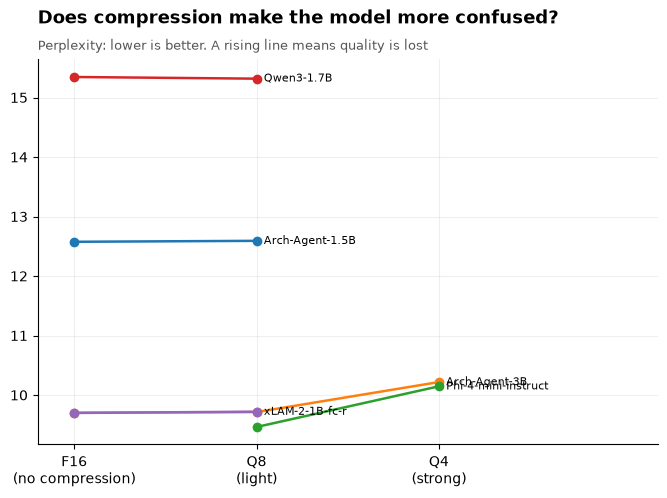

In [4]:
ppl = st.load("perplexity")
st.quant_lines(ppl, "perplexity", "Does compression make the model more confused?",
               "Perplexity: lower is better. A rising line means quality is lost", percent=False, name="08_perplexity")

## Biểu đồ 2 - Điểm chọn công cụ theo mức nén

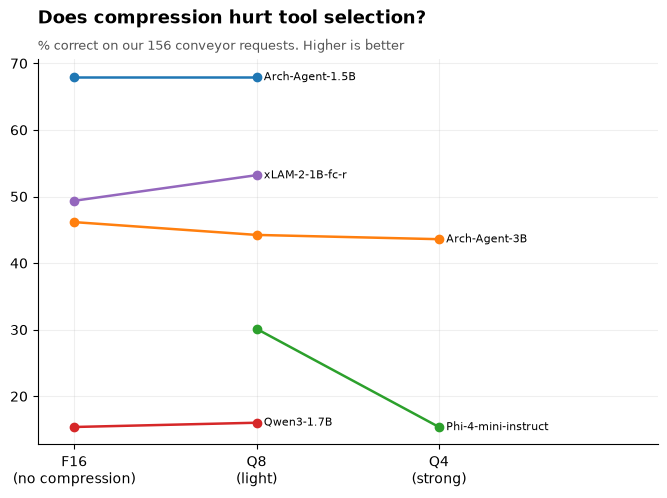

In [5]:
tool = st.load("tool_calling")
st.quant_lines(tool, "acc_all", "Does compression hurt tool selection?", "% correct on our 156 conveyor requests. Higher is better",
               name="08_tool_by_quant")

## Bảng - Mức giảm so với bản gốc F16

In [1]:
t = tool[["model", "quant", "acc_all"]].merge(ppl[["model", "quant", "perplexity"]], on=["model", "quant"], how="outer")
t = t.merge(st.load("performance")[["model", "quant", "ram_peak_mb", "file_mb"]], on=["model", "quant"], how="left")
ref = t[t.quant == "F16"].set_index("model")
t["tool_score_change_pts"] = [round((r.acc_all - ref.acc_all.get(r.model, np.nan)) * 100, 1) for r in t.itertuples()]
t["perplexity_change_pct"] = [round((r.perplexity / ref.perplexity.get(r.model, np.nan) - 1) * 100, 1) for r in t.itertuples()]
t[t.model.isin(ref.index)].sort_values(["model", "quant"])

NameError: name 'tool' is not defined